# End-to-End Physiological Synchrony Analysis: Occlusion-Aware Plot Digitization & Spectral Surrogate Testing

This notebook implements a fully transparent, reproducible pipeline that:
1. **Loads and crops** the source slide image (`Code_Generated_image.png`) into Day (Panel B, 12 h) and Night (Panel C, 8 h) regions of interest.
2. **Extracts overlapping time series** via RGB chromaticity/luminance thresholding and **occlusion-aware reconstruction** (`mal[t] = fem[t]` where the opaque foreground gray trace obscures the background orange trace), followed by 3-point binomial smoothing (`[0.25, 0.5, 0.25]`) and Z-score standardization.
3. **Evaluates statistical significance** using FFT phase-randomized surrogate time series (`phaseScrambleTS`), preserving each trace's exact power spectrum and autocorrelation structure while destroying cross-animal phase coupling.

## 1. Image Loading, Cropping & Occlusion-Aware Extraction

Standard plot-digitizing tools default to linear or spline interpolation across missing segments. When two physiological traces overlap because one curve is plotted opaquely on top of another, linear interpolation cuts across shared peaks and systematically biases cross-correlation downward. Instead, columns where the background orange curve disappears while the foreground gray curve is present are assigned the foreground coordinate (`mal[t] = fem[t]`).

In [15]:
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def extract_occluded_traces(
    img_rgb,
    crop_box,
    gray_thresh=35,
    orange_sat_thresh=40,
    overlap_px_thresh=2.5,
    zscore=True,
):
    """
    Digitizes two overlapping curves (foreground gray, background orange) from
    a cropped plot region using an occlusion-aware foreground prior.
    Flags occlusion both when orange completely vanishes (len(o_rows) == 0)
    and when partial stroke overlap brings centroids within `overlap_px_thresh`.
    """
    x0, x1, y0, y1 = crop_box
    roi = img_rgb[y0:y1, x0:x1].astype(float)
    R, G, B = roi[:, :, 0], roi[:, :, 1], roi[:, :, 2]

    channel_spread = np.max(roi, axis=2) - np.min(roi, axis=2)
    luminance = np.mean(roi, axis=2)
    gray_mask = (channel_spread < gray_thresh) & (luminance < 210)
    orange_mask = ((R - B) > orange_sat_thresh) & (R > G)

    n_cols = roi.shape[1]
    height = roi.shape[0]
    fem_y = np.full(n_cols, np.nan)
    mal_y = np.full(n_cols, np.nan)
    occlusion_mask = np.zeros(n_cols, dtype=bool)

    for col in range(n_cols):
        g_rows = np.where(gray_mask[:, col])[0]
        o_rows = np.where(orange_mask[:, col])[0]

        if len(g_rows) > 0:
            fem_y[col] = height - np.median(g_rows)

        if len(o_rows) > 0:
            raw_mal = height - np.median(o_rows)
            # If gray is present and centroids are within stroke width, partial occlusion
            # skews the visible orange edge pixels -> snap to foreground center
            if len(g_rows) > 0 and abs(fem_y[col] - raw_mal) <= overlap_px_thresh:
                mal_y[col] = fem_y[col]
                occlusion_mask[col] = True
            else:
                mal_y[col] = raw_mal
        elif len(g_rows) > 0:
            mal_y[col] = fem_y[col]
            occlusion_mask[col] = True

    cols = np.arange(n_cols)
    if np.any(np.isnan(fem_y)):
        fem_y = np.interp(cols, cols[~np.isnan(fem_y)], fem_y[~np.isnan(fem_y)])
    if np.any(np.isnan(mal_y)):
        mal_y = np.interp(cols, cols[~np.isnan(mal_y)], mal_y[~np.isnan(mal_y)])

    kernel = np.array([0.25, 0.5, 0.25])
    fem_smooth = np.convolve(np.pad(fem_y, 1, mode="edge"), kernel, mode="valid")
    mal_smooth = np.convolve(np.pad(mal_y, 1, mode="edge"), kernel, mode="valid")

    if zscore:
        fem_smooth = (fem_smooth - np.mean(fem_smooth)) / np.std(fem_smooth)
        mal_smooth = (mal_smooth - np.mean(mal_smooth)) / np.std(mal_smooth)

    return mal_smooth, fem_smooth, occlusion_mask


def get_occlusion_intervals(t, occ_mask):
    """Return list of (t_start, t_end) tuples for contiguous True runs in occ_mask."""
    padded = np.concatenate(([False], occ_mask, [False]))
    starts = np.where(padded[1:] & ~padded[:-1])[0]
    ends = np.where(~padded[1:] & padded[:-1])[0] - 1
    return [(t[s], t[e]) for s, e in zip(starts, ends)]


# Load slide image and extract
slide_path = "Code_Generated_Image.png"
img = np.array(Image.open(slide_path).convert("RGB"))

DAY_CROP_BOX = (102, 421, 102, 318)
NIGHT_CROP_BOX = (552, 763, 102, 318)

mal_day, fem_day, occ_day = extract_occluded_traces(img, DAY_CROP_BOX, overlap_px_thresh=2.5)
mal_nite, fem_nite, occ_nite = extract_occluded_traces(img, NIGHT_CROP_BOX, overlap_px_thresh=2.5)

print(f"Day occluded:   {occ_day.mean():.1%} ({occ_day.sum()}/{len(occ_day)} cols)")
print(f"Night occluded: {occ_nite.mean():.1%} ({occ_nite.sum()}/{len(occ_nite)} cols)")

Day occluded:   14.7% (47/319 cols)
Night occluded: 13.3% (28/211 cols)


## 2. Crop & Occlusion Diagnostic Verification

Visualizing the crop boxes on the source image alongside the reconstructed traces (highlighting occluded columns in red) verifies that axis spines are excluded and shared peaks are faithfully recovered.

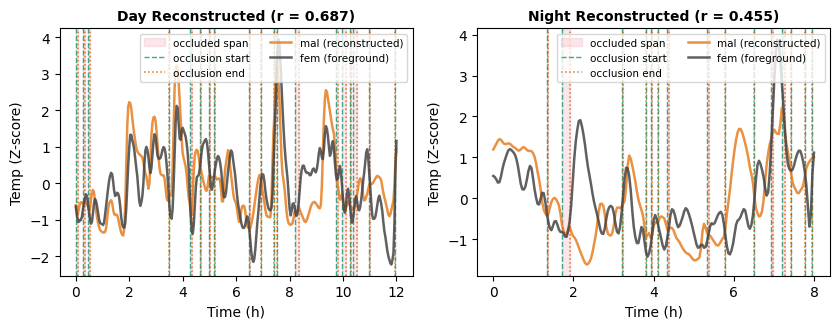

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))

for ax, t_max, mal, fem, occ, title in [
    (axes[0], 12.0, mal_day, fem_day, occ_day, "Day Reconstructed"),
    (axes[1], 8.0, mal_nite, fem_nite, occ_nite, "Night Reconstructed"),
]:
    t = np.linspace(0, t_max, len(mal))
    intervals = get_occlusion_intervals(t, occ)

    for idx, (t_start, t_end) in enumerate(intervals):
        ax.axvspan(t_start, t_end, color="crimson", alpha=0.10,
                   label="occluded span" if idx == 0 else None)
        ax.axvline(t_start, color="#1b9e77", linestyle="--", lw=1.0, alpha=0.85,
                   label="occlusion start" if idx == 0 else None)
        ax.axvline(t_end, color="#d95f02", linestyle=":", lw=1.1, alpha=0.85,
                   label="occlusion end" if idx == 0 else None)

    ax.plot(t, mal, color="#E67E22", alpha=0.85, lw=1.8, label="mal (reconstructed)")
    ax.plot(t, fem, color="#444444", alpha=0.85, lw=1.8, label="fem (foreground)")
    ax.set_title(f"{title} (r = {np.corrcoef(mal, fem)[0,1]:.3f})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Time (h)")
    ax.set_ylabel("Temp (Z-score)")
    ax.legend(fontsize=7.5, loc="upper right", ncol=2)

plt.tight_layout()
plt.show()

## 3. FFT Phase-Randomized Surrogate Significance Testing

To test whether observed dyadic correlation exceeds what is expected from slow circadian or ultradian autocorrelation alone, we generate $N = 1{,}000$ phase-scrambled surrogates for each window and compare the empirical Pearson $r$ against the 99.9th percentile of the null distribution.

Day (12 h, detrended):   R = 0.687 | 99.9% null = 0.540 | AS = 1.272 | p = 0.0010
Night (8 h, detrended):  R = 0.453 | 99.9% null = 0.604 | AS = 0.750 | p = 0.0669


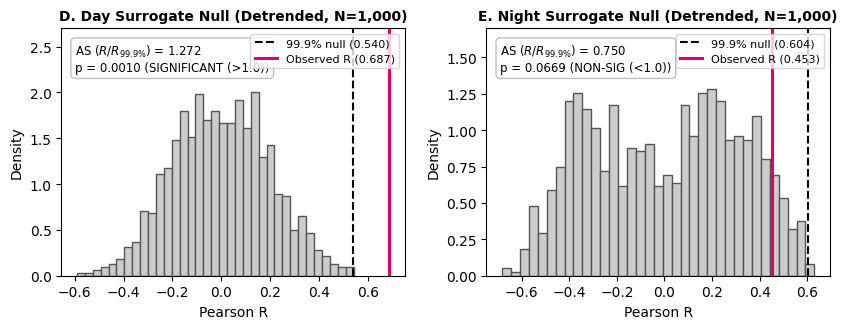

In [25]:
from scipy.signal import detrend


def phaseScrambleTS(ts, rng=None):
    """Generate a phase-randomized surrogate preserving the exact amplitude spectrum."""
    if rng is None:
        rng = np.random.default_rng()
    ts = np.asarray(ts, dtype=float)
    n = len(ts)
    fft_vals = np.fft.rfft(ts)
    amplitudes = np.abs(fft_vals)
    phases = np.angle(fft_vals)

    random_phases = rng.uniform(0, 2 * np.pi, size=len(fft_vals))
    random_phases[0] = phases[0]  # Preserve DC component
    if n % 2 == 0:
        random_phases[-1] = phases[-1]  # Preserve Nyquist phase if even length

    surrogate_fft = amplitudes * np.exp(1j * random_phases)
    return np.fft.irfft(surrogate_fft, n=n)


def preprocess_for_synchrony(ts):
    """Linearly detrend and Z-score normalize a time series prior to surrogate testing."""
    ts_dt = detrend(np.asarray(ts, dtype=float), type="linear")
    return (ts_dt - np.mean(ts_dt)) / np.std(ts_dt)


def compute_surrogate_significance(ts1, ts2, n_surrogates=1000, seed=42, apply_detrend=True):
    """
    Compute empirical Pearson r, 99.9th-percentile surrogate threshold,
    Arbitrary Significance ratio (AS = r_obs / r_99.9%), and empirical p-value.
    """
    if apply_detrend:
        ts1 = preprocess_for_synchrony(ts1)
        ts2 = preprocess_for_synchrony(ts2)

    rng = np.random.default_rng(seed)
    r_obs = np.corrcoef(ts1, ts2)[0, 1]
    r_null = np.empty(n_surrogates)

    for i in range(n_surrogates):
        s1 = phaseScrambleTS(ts1, rng=rng)
        s2 = phaseScrambleTS(ts2, rng=rng)
        r_null[i] = np.corrcoef(s1, s2)[0, 1]

    thresh_999 = np.percentile(r_null, 99.9)
    as_ratio = r_obs / thresh_999 if thresh_999 > 0 else np.nan
    p_val = (np.sum(r_null >= r_obs) + 1) / (n_surrogates + 1)
    return r_obs, thresh_999, as_ratio, p_val, r_null


r_day, thresh_day, as_day, p_day, null_day = compute_surrogate_significance(
    mal_day, fem_day, apply_detrend=True
)
r_nite, thresh_nite, as_nite, p_nite, null_nite = compute_surrogate_significance(
    mal_nite, fem_nite, apply_detrend=True
)

print(f"Day (12 h, detrended):   R = {r_day:.3f} | 99.9% null = {thresh_day:.3f} | AS = {as_day:.3f} | p = {p_day:.4f}")
print(f"Night (8 h, detrended):  R = {r_nite:.3f} | 99.9% null = {thresh_nite:.3f} | AS = {as_nite:.3f} | p = {p_nite:.4f}")

# Plot surrogate null distributions with Arbitrary Significance (AS)
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax, null_dist, r_obs, thresh, as_val, p_val, y_max, title in [
    (axes[0], null_day, r_day, thresh_day, as_day, p_day, 2.7, "D. Day Surrogate Null (Detrended, N=1,000)"),
    (axes[1], null_nite, r_nite, thresh_nite, as_nite, p_nite, 1.7, "E. Night Surrogate Null (Detrended, N=1,000)"),
]:
    ax.hist(null_dist, bins=35, color="#cccccc", edgecolor="#555555", density=True)
    ax.axvline(thresh, color="black", linestyle="--", lw=1.5, label=f"99.9% null ({thresh:.3f})")
    ax.axvline(r_obs, color="#d90077", lw=2.2, label=f"Observed R ({r_obs:.3f})")

    status = "SIGNIFICANT (>1.0)" if as_val > 1.0 else "NON-SIG (<1.0)"
    stats_text = (
        f"AS ($R / R_{{99.9\\%}}$) = {as_val:.3f}\n"
        f"p = {p_val:.4f} ({status})"
    )
    ax.text(
        0.04, 0.94, stats_text,
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=8.5,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#bbbbbb", alpha=0.92),
    )

    ax.set_ylim(0, y_max)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xlabel("Pearson R")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()